# Steam Publishing EDA

The goal of this project is to compare self-published games vs. traditionally published games on Steam.

I will be using a publicly available dataset which has updated listings as of October 2025. There will be a guide on how to acquire this data in the README.

Each section will have markdown text that explains my thought processes behind all my decisions.

## Section 0: Set Up

Here is all the code needed to import the necessary libraries for this project. 

In [1]:
import numpy as np

import polars as pl

%matplotlib inline
import matplotlib.pyplot as plt
from sklearn import linear_model as lm

import warnings
warnings.filterwarnings("ignore")

import zipfile
import os

# Plot settings
plt.rcParams['figure.figsize'] = (12, 9)
plt.rcParams['font.size'] = 12

The next step is to read the relevant csv files for this project. Starting with applications.csv, which has the most amount of information.

In [2]:
apps = pl.read_csv(
    "steam_dataset_2025_csv/applications.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

As is, the apps dataframe has many unnecessary columns. It also is missing key information about developers, genres, publishers, etc.

I'll have to read the remaining files, and join based on appid. Then, I'll have to make more joins based on publisher id and so on.

In [3]:
appDev = pl.read_csv(
    "steam_dataset_2025_csv/application_developers.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

appGenres = pl.read_csv(
    "steam_dataset_2025_csv/application_genres.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

appPub = pl.read_csv(
    "steam_dataset_2025_csv/application_publishers.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

devs = pl.read_csv(
    "steam_dataset_2025_csv/developers.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

genres = pl.read_csv(
    "steam_dataset_2025_csv/genres.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

publishers = pl.read_csv(
    "steam_dataset_2025_csv/publishers.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)




In [4]:
steam = apps.select(['appid', 'name', 'type', 'is_free', 'release_date', "mat_initial_price", "mat_final_price", "mat_currency", "recommendations_total", "created_at", "updated_at"])

The steam dataframe is much easier to deal with than the original apps dataframe. 

Now I need to join the other dataframes I've created into one big dataframe that I can use for proper data analysis.

In [5]:
steam = steam.join(appDev, on="appid")
steam = steam.join(appGenres, on="appid")
steam = steam.join(appPub, on="appid")

In [6]:
devs = devs.rename({"id" : "developer_id"}).rename({"name" : "developer"})
genres = genres.rename({"id" : "genre_id"}).rename({"name" : "genre"})
publishers = publishers.rename({"id" : "publisher_id"}).rename({"name" : "publisher"})

steam = steam.join(devs, on="developer_id")
steam = steam.join(genres, on="genre_id")
steam = steam.join(publishers, on="publisher_id")

## Section 1: EDA

To get a proper idea of the data I'm working with, I'll start by taking a sample of five rows from the steam data frame.

In [13]:
steam.tail(5)

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,created_at,updated_at,developer_id,genre_id,publisher_id,developer,genre,publisher
i64,str,str,bool,date,f64,f64,str,f64,"datetime[μs, UTC]","datetime[μs, UTC]",i64,i64,i64,str,str,str
3992900,"""Hero of Sunset Demo""","""demo""",true,null,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,60656,113,56486,"""Starfall Games""","""Adventure""","""Flowing Dreams"""
3992900,"""Hero of Sunset Demo""","""demo""",true,null,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,60656,122,56486,"""Starfall Games""","""Action""","""Flowing Dreams"""
3992900,"""Hero of Sunset Demo""","""demo""",true,null,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,60656,144,56486,"""Starfall Games""","""RPG""","""Flowing Dreams"""
3996190,"""Project: Haste Demo""","""demo""",true,2025-09-02,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,88993,31,75321,"""Pronto Games Inc""","""Indie""","""Pronto Games Inc"""
3996190,"""Project: Haste Demo""","""demo""",true,2025-09-02,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,88993,122,75321,"""Pronto Games Inc""","""Action""","""Pronto Games Inc"""


After running the sample a few times, I noticed some features which I'd like to filter out.

What I'm interested in comparing are released games. So I plan on filtering the dataframe where "type" == "game" and "release_date" is not null.

This way, I get rid of any DLCs and demos, as well as unreleased video games.

In [16]:
steam = steam.filter(pl.col("type") == "game")
steam = steam.filter(pl.col("release_date").is_not_null())

Now I will add a new column of booleans that indicate whether or not a game is self-published.

To do this, I will compare the strings of the developer and publisher columns. As seen in the first five rows of the dataframe, the developer_id and publisher_id columns for Valve do not match each other, even though they are the same. So I will be comparing the strings instead.

In [21]:
steam.head(5)

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,created_at,updated_at,developer_id,genre_id,publisher_id,developer,genre,publisher
i64,str,str,bool,date,f64,f64,str,f64,"datetime[μs, UTC]","datetime[μs, UTC]",i64,i64,i64,str,str,str
10,"""Counter-Strike""","""game""",false,2000-11-01,999.0,999.0,"""USD""",161854.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve"""
20,"""Team Fortress Classic""","""game""",false,1999-04-01,499.0,499.0,"""USD""",6633.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve"""
30,"""Day of Defeat""","""game""",false,2003-05-01,499.0,499.0,"""USD""",4308.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve"""
40,"""Deathmatch Classic""","""game""",false,2001-06-01,499.0,499.0,"""USD""",2338.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve"""
50,"""Half-Life: Opposing Force""","""game""",false,1999-11-01,499.0,499.0,"""USD""",22793.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,21806,122,50182,"""Gearbox Software""","""Action""","""Valve"""


In [ ]:
steam = steam.with_columns(
    (pl.col("developer") == pl.col("publisher")).alias("self-published")
)

We can verify that the new column was created correctly by looking at the first five rows again.

In [25]:
steam.head(5)

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,created_at,updated_at,developer_id,genre_id,publisher_id,developer,genre,publisher,self-published
i64,str,str,bool,date,f64,f64,str,f64,"datetime[μs, UTC]","datetime[μs, UTC]",i64,i64,i64,str,str,str,bool
10,"""Counter-Strike""","""game""",false,2000-11-01,999.0,999.0,"""USD""",161854.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve""",true
20,"""Team Fortress Classic""","""game""",false,1999-04-01,499.0,499.0,"""USD""",6633.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve""",true
30,"""Day of Defeat""","""game""",false,2003-05-01,499.0,499.0,"""USD""",4308.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve""",true
40,"""Deathmatch Classic""","""game""",false,2001-06-01,499.0,499.0,"""USD""",2338.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve""",true
50,"""Half-Life: Opposing Force""","""game""",false,1999-11-01,499.0,499.0,"""USD""",22793.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,21806,122,50182,"""Gearbox Software""","""Action""","""Valve""",false


Now the first thing I want to know is how many self-published games there are compared to traditionally published games. To do this I will make a bar plot.

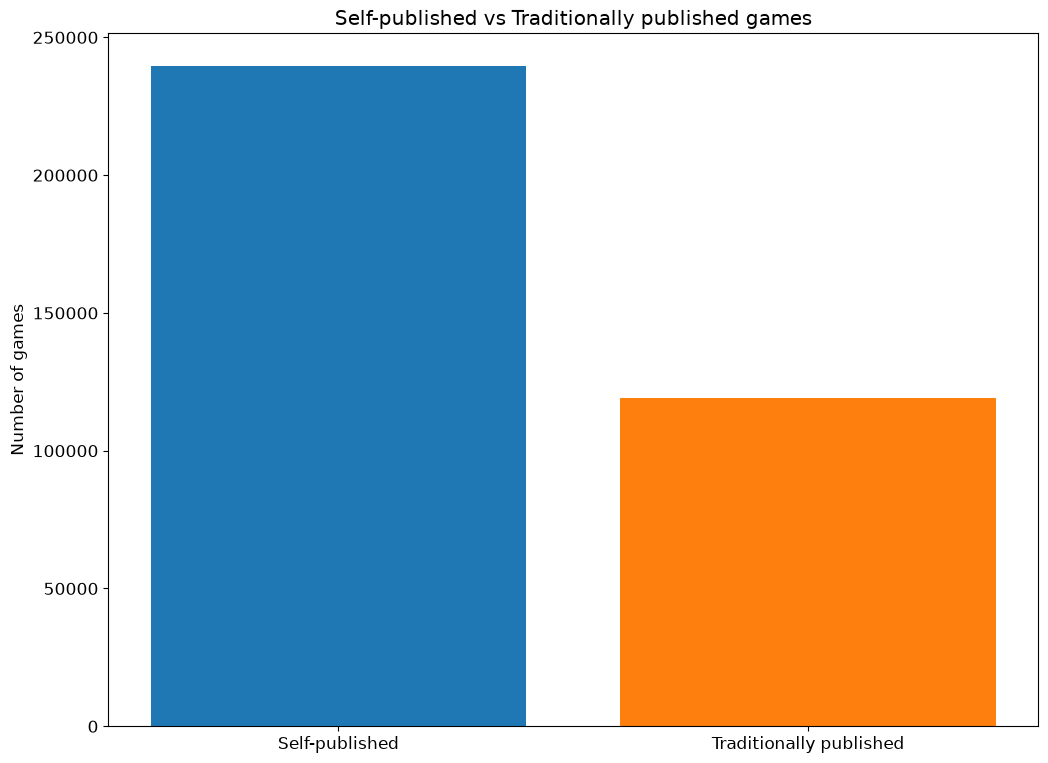

In [27]:
plot_df = (
    steam
    .select(
        pl.when(pl.col("self-published"))
          .then(pl.lit("Self-published"))
          .otherwise(pl.lit("Traditionally published"))
          .alias("category")
    )
    .group_by("category")
    .len()
)

fig, ax = plt.subplots()
ax.bar(plot_df["category"], plot_df["len"], color=["tab:blue", "tab:orange"])
ax.set_ylabel("Number of games")
ax.set_title("Self-published vs Traditionally published games")
plt.show()

This is not what I was expecting. I want to make a line plot to see how the amount of games within each publishing style has changed over time.

Is there a point where there have been more self-published games being made each year?

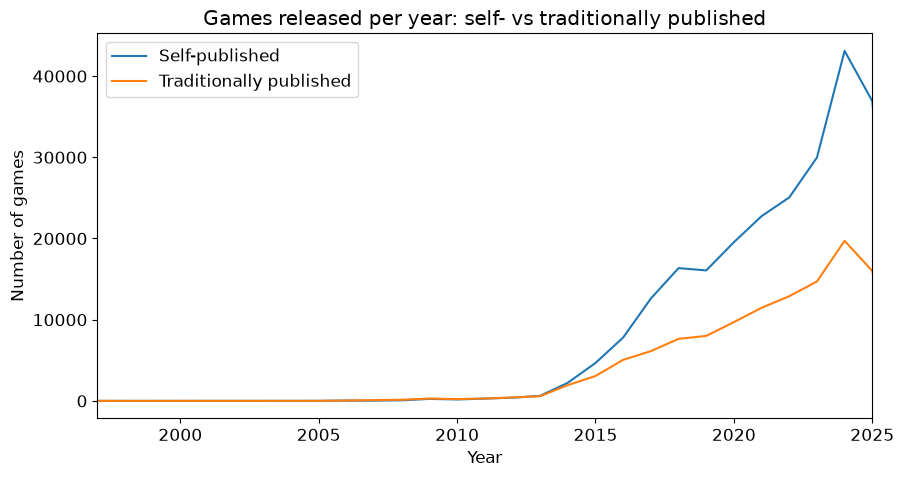

In [ ]:
plot_df = (
    steam
    .with_columns(
        pl.col("release_date").dt.year().alias("year")
    )
    .group_by("year", "self-published")
    .len()
    .sort("year")
)

fig, ax = plt.subplots(figsize=(10, 5))

for is_self, label in [(True, "Self-published"), (False, "Traditionally published")]:
    sub = plot_df.filter(pl.col("self-published") == is_self).sort("year")
    ax.plot(sub["year"], sub["len"], label=label)

ax.set_xlabel("Year")
ax.set_ylabel("Number of games")
ax.set_title("Games released per year: self- vs traditionally published")

# Every 5 years, ending on 2025
ax.set_xticks(range(1995, 2026, 5))
ax.set_xlim(1997, 2025)

ax.legend()
plt.show()